# Is the 60/40 Portfolio Still Diversified?

**Question:** Do US bonds still diversify an equity portfolio, or have stocks and bonds started moving together?

**Short answer:** Over 2004–2024 as a whole, daily stock and bond returns look unrelated (correlation ≈ 0). That average hides two opposite regimes. Before 2020 the correlation was mostly **negative**, so bonds cushioned equity drawdowns. Since 2020 it has been mostly **positive**, so bonds and stocks have tended to fall together, which weakens the diversification a 60/40 portfolio relies on.

| | |
|---|---|
| **Equities** | SPY (S&P 500 ETF), total return (prices adjusted for dividends) |
| **Bonds** | AGG (iShares Core US Aggregate Bond ETF), total return |
| **Period** | AGG inception (late 2003) to 2024-12-31 |
| **Source** | Yahoo Finance via `yfinance` |
| **Tools** | Python, pandas, statsmodels, matplotlib, seaborn |

## Summary

### How I approached it
1. **Start with the simple test.** Regress stock returns on bond returns over the whole 2004–2024 period. Result: no relationship on daily data (correlation -0.01, p = 0.76), but a positive, significant one on monthly data (+0.23, p = 0.003). Those two answers disagree, which suggested the relationship was not stable over time.
2. **Check whether the relationship changed over time.** Plot rolling correlations. The 3-month window shows when the sign changes, and the 6-month and 1-year windows show whether the change lasts. All point to a flip from negative to positive in early 2020.
3. **Test the shift formally.** Split the sample at 2020 and rerun the regression for each period, on both daily and monthly returns, with standard errors that account for volatile, autocorrelated returns.
4. **Interpret the horizon.** Compare daily and monthly results to see where the effect is strongest, since a 60/40 investor rebalances and measures risk over months, not days.

### What I found

| | 2004–2019 | 2020–2024 |
|---|---|---|
| Daily correlation | -0.12 (not significant, p = 0.11) | **+0.19** (p = 0.001) |
| Monthly correlation | 0.00 (p = 0.97) | **+0.57** (p < 0.001) |
| Monthly R-squared | 0.00 | **0.32** |

- **The relationship flipped in 2020.** Before 2020, bonds were uncorrelated to slightly negative with stocks, so they diversified a 60/40 portfolio. Since 2020, stocks and bonds have moved together, significantly on both daily and monthly data.
- **The effect is strongest monthly.** Daily returns are noisy (one-off news, flight-to-safety days). Over a month that noise averages out, leaving the shared drivers: inflation and interest-rate expectations. Since 2020, bond returns explain about a third of monthly stock returns.
- **This resolves the puzzle from step 1.** The full-period daily result looks like zero because the negative pre-2020 regime and the positive post-2020 regime cancel out. The full-period monthly result is positive because the post-2020 years drive it.
- **Context:** positive stock-bond correlation is not new (it was briefly positive in 2005–2007). It tends to appear when inflation is the dominant risk, as it was from 2021.

### Method choices
- **Data:** SPY and AGG adjusted closes (total returns). Positive correlation means stocks and bonds moved in the same direction.
- **Regression:** OLS of SPY returns on AGG returns. Standard errors are HAC (Newey-West), which corrects for changing volatility and autocorrelation in returns, so significance is not overstated.
- **Regime split at 2020:** chosen from the rolling correlations, which show the break there. A formal structural-break test is listed as a next step.
- **Rolling windows count trading days** (about 252 a year): 63 days ≈ 3 months, 126 ≈ 6 months, 252 ≈ 1 year. A correlation's sampling error is roughly 1/√n, so 63 days (about ±0.13) is the shortest window precise enough to tell +0.2 from zero, while 252 days (about ±0.06) is stable but slower. Using three windows checks that the result does not depend on the window chosen.

## Method

1. **Data:** download adjusted daily closes for SPY and AGG and compute daily and month-end returns.
2. **Full-period regression:** regress equity returns on bond returns (OLS with heteroskedasticity- and autocorrelation-robust standard errors).
3. **Rolling correlation:** 63-day (~3 months), 126-day (~6 months), and 252-day (~1 year) windows to show how the relationship changes over time.
4. **Regime regressions:** repeat the regression separately for 2004–2019 and 2020–2024, on daily and monthly data.

## Install packages

Run once per session (needed in Colab; skip if the packages are already installed).

In [1]:
!pip install -q yfinance statsmodels seaborn

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

START, END = "2003-09-29", "2025-01-01"   # AGG began trading in late September 2003
REGIME_BREAK = "2020-01-01"
sns.set_theme(style="white")

## 1. Data

In [3]:
prices = yf.download(["SPY", "AGG"], start=START, end=END, auto_adjust=True, progress=False)["Close"]
prices = prices.rename(columns={"SPY": "Equities", "AGG": "Bonds"})[["Equities", "Bonds"]].dropna()

daily = prices.pct_change().dropna()
monthly = prices.resample("ME").last().pct_change().dropna()

print(f"Daily observations:   {len(daily):,}  ({daily.index.min().date()} to {daily.index.max().date()})")
print(f"Monthly observations: {len(monthly):,}")

Daily observations:   5,350  (2003-09-30 to 2024-12-31)
Monthly observations: 255


## 2. Full-period regression

In [4]:
def regress(df, label):
    X = sm.add_constant(df["Bonds"])
    res = sm.OLS(df["Equities"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return {"Sample": label, "Obs": int(res.nobs), "Beta": res.params["Bonds"],
            "t-stat": res.tvalues["Bonds"], "p-value": res.pvalues["Bonds"],
            "R-squared": res.rsquared, "Correlation": df["Equities"].corr(df["Bonds"])}

full = pd.DataFrame([regress(daily, "Daily, full period"), regress(monthly, "Monthly, full period")]).set_index("Sample")
full.round(3)

,Obs,Beta,t-stat,p-value,R-squared,Correlation
Sample,,,,,,
"Daily, full period",5350,-0.048,-0.309,0.757,0.000,-0.013
"Monthly, full period",255,0.759,3.002,0.003,0.054,0.233


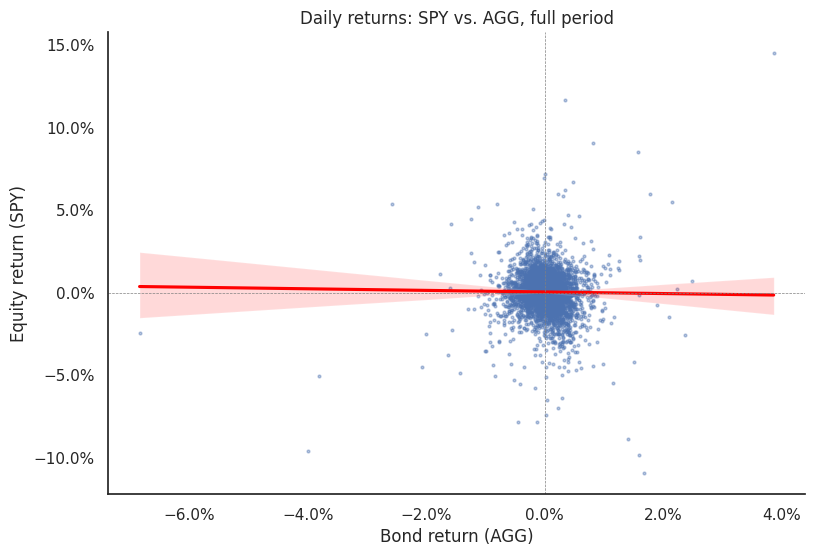

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(x="Bonds", y="Equities", data=daily, scatter_kws={"s": 4, "alpha": 0.4}, line_kws={"color": "red"}, ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.axhline(0, color="gray", lw=0.5, ls="--"); ax.axvline(0, color="gray", lw=0.5, ls="--")
ax.set(title="Daily returns: SPY vs. AGG, full period", xlabel="Bond return (AGG)", ylabel="Equity return (SPY)")
sns.despine(); plt.show()

Over the full period the slope is close to zero and not statistically significant. The next section shows why: the relationship changed sign, and the two regimes cancel out in a single regression.

## 3. Rolling correlation

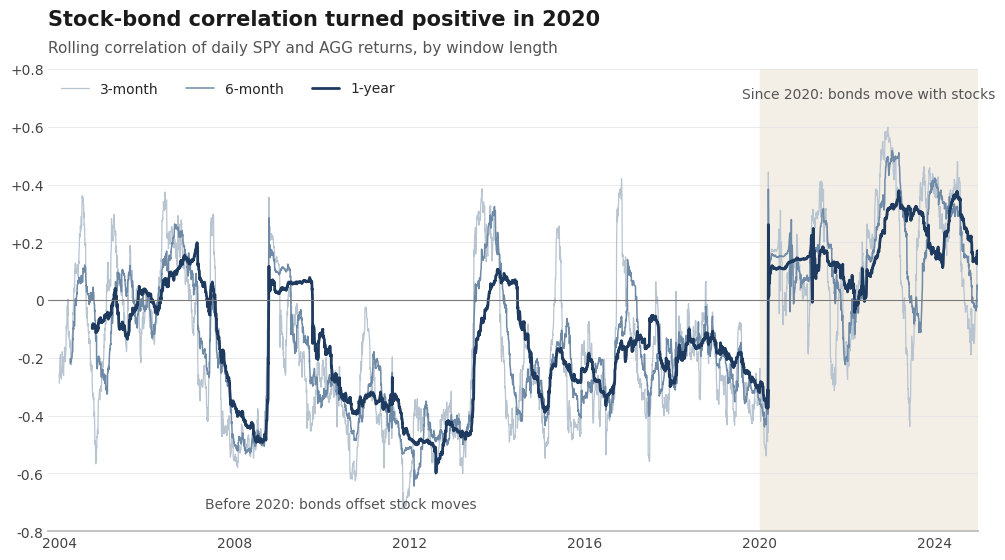

In [6]:
windows = [(63, "3-month", "#B8C4D0", 0.9), (126, "6-month", "#6F8AA6", 1.1), (252, "1-year", "#1F3A5F", 2.0)]
break_date = pd.Timestamp(REGIME_BREAK)

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(break_date, daily.index.max(), color="#F3EFE7", zorder=0)
for window, label, color, lw in windows:
    ax.plot(daily["Equities"].rolling(window).corr(daily["Bonds"]), color=color, lw=lw, label=label)

ax.axhline(0, color="#7A7A7A", lw=0.8)
ax.set_ylim(-0.8, 0.8)
ax.set_xlim(daily.index.min(), daily.index.max())
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.1f}" if v else "0"))
ax.grid(axis="y", color="#E6E6E6", lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(length=0, labelsize=10, colors="#444444")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.set_xlabel(""); ax.set_ylabel("")

ax.text(pd.Timestamp("2010-06-01"), -0.72, "Before 2020: bonds offset stock moves", ha="center", fontsize=10, color="#555555")
ax.text(break_date + (daily.index.max() - break_date) / 2, 0.70, "Since 2020: bonds move with stocks",
        ha="center", fontsize=10, color="#555555")

fig.suptitle("Stock-bond correlation turned positive in 2020", x=0.125, y=0.98, ha="left", fontsize=15, fontweight="bold", color="#1A1A1A")
ax.set_title("Rolling correlation of daily SPY and AGG returns, by window length", loc="left", fontsize=11, color="#555555", pad=12)
ax.legend(loc="upper left", frameon=False, ncol=3, fontsize=10, bbox_to_anchor=(0, 1.0))
plt.show()

## 4. Regime regressions: before and after 2020

In [7]:
pre_d, post_d = daily[:REGIME_BREAK], daily[REGIME_BREAK:]
pre_m, post_m = monthly[:REGIME_BREAK], monthly[REGIME_BREAK:]
regimes = pd.DataFrame([
    regress(pre_d, "Daily, 2004-2019"), regress(post_d, "Daily, 2020-2024"),
    regress(pre_m, "Monthly, 2004-2019"), regress(post_m, "Monthly, 2020-2024"),
]).set_index("Sample")
regimes.round(3)

,Obs,Beta,t-stat,p-value,R-squared,Correlation
Sample,,,,,,
"Daily, 2004-2019",4092,-0.462,-1.590,0.112,0.014,-0.119
"Daily, 2020-2024",1258,0.570,3.388,0.001,0.034,0.185
"Monthly, 2004-2019",195,0.014,0.035,0.972,0.000,0.004
"Monthly, 2020-2024",60,1.587,7.986,0.000,0.321,0.567


## Findings

| Sample | Obs | Beta | t-stat | p-value | R-squared | Correlation |
|---|---|---|---|---|---|---|
| Daily, full period | 5,350 | -0.05 | -0.31 | 0.757 | 0.000 | -0.01 |
| Monthly, full period | 255 | 0.76 | 3.00 | 0.003 | 0.054 | 0.23 |
| Daily, 2004-2019 | 4,092 | -0.46 | -1.59 | 0.112 | 0.014 | -0.12 |
| Daily, 2020-2024 | 1,258 | 0.57 | 3.39 | 0.001 | 0.034 | 0.19 |
| Monthly, 2004-2019 | 195 | 0.01 | 0.04 | 0.972 | 0.000 | 0.00 |
| Monthly, 2020-2024 | 60 | 1.59 | 7.99 | <0.001 | 0.321 | 0.57 |

*OLS of SPY returns on AGG returns with HAC (Newey-West) standard errors.*

- **The relationship changed sign around 2020.** Before 2020, stocks and bonds were uncorrelated to slightly negative (daily correlation -0.12, monthly 0.00), so bonds diversified equity risk. Since 2020 they have moved together: daily correlation +0.19 and monthly +0.57, both statistically significant (p ≤ 0.001).
- **The effect is strongest at the monthly horizon.** From 2020 to 2024, bond returns explain about a third of the variation in monthly equity returns (R-squared 0.32), against essentially none before 2020. Monthly is closer to the horizon at which most investors rebalance and measure risk.
- **A full-period regression hides the change.** Over 2004-2024 the daily relationship looks like zero (p = 0.76) because the negative pre-2020 regime and the positive post-2020 regime offset each other. The full-period monthly result (correlation +0.23) is driven by the post-2020 years.
- **Implication:** since 2020, a 60/40 portfolio has received much less diversification from bonds than its historical track record suggests, especially in months when inflation and rate shocks hit both asset classes at once (for example, 2022).

## Limitations and next steps

- Two ETFs stand in for each asset class. Results could differ for long-duration Treasuries (e.g. TLT) or international markets.
- The 2020 break is chosen by eye. A formal structural-break test (e.g. Chow or Bai-Perron) would make it more rigorous.
- Correlation regimes are commonly linked to inflation. Adding CPI or breakeven inflation as an explanatory variable is a natural extension.